# Kurulu Gee: Predicting Bird Diversity in Sri Lanka with Ensemble Learning
**Module hands-on project: Bagging, Boosting, Stacking and a hybrid RF + ANN model**

**Student:** Siriwardhana M.S.H.N. (224186C)

**Dataset:** Sri Lanka Bird Diversity Dataset with Environmental and Climate Features
(Hugging Face: `Bird-Diversity/Diversity`, licence CC BY 4.0), 2014–2024, 25 districts.

**GenAI disclosure:** Parts of this notebook's code and the Streamlit dashboard were generated
with AI assistants (Claude and GitHub Copilot). I reviewed, ran and adjusted all of the code,
and the analysis and interpretation are my own.

## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_predict, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor,
                              AdaBoostRegressor, StackingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from lightgbm import LGBMRegressor

SEED = 42
np.random.seed(SEED)
os.makedirs("artifacts", exist_ok=True)

## 2. Load the raw data

In [2]:
# Option A (easiest): download straight from Hugging Face (needs `pip install datasets`)
# from datasets import load_dataset
# raw = load_dataset("Bird-Diversity/Diversity", split="train").to_pandas()
#
# Option B: you downloaded the file yourself into the data/ folder
DATA_PATH = "data/bird_diversity.csv"          # change to your file name
if DATA_PATH.endswith(".parquet"):
    raw = pd.read_parquet(DATA_PATH)
else:
    raw = pd.read_csv(DATA_PATH, low_memory=False)

print(raw.shape)
raw.head()

(1552048, 24)


,index,verbatimScientificName,stateProvince,individualCount,decimalLatitude,decimalLongitude,eventDate,avg_rad,NDVI_raw,LandCover_Class,...,Sulfate_Mass,Sea_Salt_Mass,Total_Aerosol_Extinction,temp_mean,rainfall,wind_mean,humid_mean,shortwave_radiation,lka_general_2020,NDVI
0,0,Anarhynchus alexandrinus,Mannar,8.0,9.058512,79.85502,2021-01-06,0.66,3792.0,10,...,3.372161e-09,3.725563e-08,0.175115,26.58,15.17,1.31,85.53,17.65,2.805795,0.3792
1,2,Hirundo rustica,Colombo,10.0,6.866285,79.93144,2024-12-23,10.16,7045.0,13,...,4.424376e-09,3.249729e-08,0.198127,26.21,0.25,2.51,84.30,20.49,8.917330,0.7045
2,6,Corvus macrorhynchos,Matara,2.0,5.983496,80.52548,2024-10-12,1.26,6989.0,10,...,7.456183e-10,5.362027e-08,0.131458,26.91,14.47,5.18,83.81,15.67,2.768103,0.6989
3,7,Dicrurus caerulescens,Matale,1.0,7.969125,80.75477,2021-11-20,0.37,8543.0,8,...,1.612494e-09,3.017664e-08,0.123156,25.30,2.54,2.98,89.54,21.99,3.339740,0.8543
4,8,Threskiornis melanocephalus,Jaffna,30.0,9.637712,79.95190,2019-03-25,0.52,4000.0,10,...,2.737918e-09,3.224930e-08,0.220155,29.67,0.00,4.65,63.33,24.53,3.209018,0.4000


## 3. Quick look

In [3]:
print(raw.dtypes)
print("\nMissing values (%):")
print((raw.isna().mean() * 100).round(2).sort_values(ascending=False).head(10))
print("\nDistricts:", raw["stateProvince"].nunique())
print("Species:", raw["verbatimScientificName"].nunique())

index                         int64
verbatimScientificName          str
stateProvince                   str
individualCount             float64
decimalLatitude             float64
decimalLongitude            float64
eventDate                       str
avg_rad                     float64
NDVI_raw                    float64
LandCover_Class               int64
elevation_meters              int64
Carbon_Mass                 float64
Dust_Mass                   float64
SO2_Mass                    float64
Sulfate_Mass                float64
Sea_Salt_Mass               float64
Total_Aerosol_Extinction    float64
temp_mean                   float64
rainfall                    float64
wind_mean                   float64
humid_mean                  float64
shortwave_radiation         float64
lka_general_2020            float64
NDVI                        float64
dtype: object

Missing values (%):
index                     0.0
verbatimScientificName    0.0
stateProvince             0.0
individualC

## 4. Clean

In [4]:
df = raw.copy()

# 4a. District names: remove extra words / spaces so "Colombo District" == "Colombo"
df["district"] = (df["stateProvince"].astype(str)
                  .str.replace(r"\s*(District|Province)$", "", regex=True)
                  .str.strip().str.title())

# 4b. Dates: some GBIF dates are ranges like "2019-05-01/2019-05-31" -> keep the first date
df["date"] = pd.to_datetime(df["eventDate"].astype(str).str[:10], errors="coerce")

# 4c. Drop rows we cannot use
df = df.dropna(subset=["district", "date", "verbatimScientificName"])
df = df[(df["date"].dt.year >= 2014) & (df["date"].dt.year <= 2024)]
df = df[df["district"].str.lower() != "nan"]

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
print(df.shape, "| districts:", sorted(df["district"].unique()))

(1552048, 28) | districts: ['Ampara', 'Anuradhapura', 'Badulla', 'Batticaloa', 'Colombo', 'Galle', 'Gampaha', 'Hambantota', 'Jaffna', 'Kalutara', 'Kandy', 'Kegalla', 'Kilinochchi', 'Kurunegala', 'Mannar', 'Matale', 'Matara', 'Monaragala', 'Mullaittivu', 'Nuwara', 'Polonnaruwa', 'Puttalam', 'Ratnapura', 'Trincomalee', 'Vavuniya']


## 5. Build the modelling table: one row per district per month

In [5]:
ENV_COLS = ["NDVI", "elevation_meters", "temp_mean", "rainfall", "wind_mean",
            "humid_mean", "shortwave_radiation", "avg_rad", "lka_general_2020",
            "Total_Aerosol_Extinction"]

agg = (df.groupby(["district", "year", "month"])
         .agg(species_richness=("verbatimScientificName", "nunique"),   # TARGET
              n_records=("verbatimScientificName", "size"),              # survey effort
              lat=("decimalLatitude", "mean"),
              lon=("decimalLongitude", "mean"),
              **{c: (c, "mean") for c in ENV_COLS})
         .reset_index())

# Drop very thin months (fewer than 20 sightings) - richness there is mostly noise
agg = agg[agg["n_records"] >= 20].copy()

# Feature engineering
agg["log_records"] = np.log1p(agg["n_records"])            # effort has diminishing returns
agg["month_sin"] = np.sin(2 * np.pi * agg["month"] / 12)   # Dec and Jan are neighbours
agg["month_cos"] = np.cos(2 * np.pi * agg["month"] / 12)
agg["migrant_season"] = agg["month"].isin([9, 10, 11, 12, 1, 2, 3, 4]).astype(int)

# Fill remaining gaps in environment columns with the district median
for c in ENV_COLS:
    agg[c] = agg[c].fillna(agg.groupby("district")[c].transform("median")).fillna(agg[c].median())

print(agg.shape)
agg.describe().T

(2079, 21)


,count,mean,std,min,25%,50%,75%,max
year,2079.0,2019.729678,3.057366,2014.000000,2017.000000,2.020000e+03,2022.000000,2024.000000
month,2079.0,6.222222,3.640044,1.000000,3.000000,6.000000e+00,10.000000,12.000000
species_richness,2079.0,88.146224,43.428609,7.000000,53.000000,8.600000e+01,117.000000,226.000000
n_records,2079.0,745.134199,1223.618527,20.000000,89.000000,2.800000e+02,816.000000,9414.000000
lat,2079.0,7.245412,0.901269,5.947432,6.530362,7.001707e+00,7.839742,9.809041
lon,2079.0,80.528941,0.481880,79.698555,80.134820,8.050138e+01,80.876580,81.850133
NDVI,2079.0,0.668762,0.134657,-0.073100,0.589088,6.950000e-01,0.769399,0.913200
elevation_meters,2079.0,258.724899,444.117035,0.000000,12.596785,8.000000e+01,233.084380,2133.814815
temp_mean,2079.0,26.033081,1.891042,20.451606,24.832323,2.629819e+01,27.327117,31.827689
rainfall,2079.0,5.116353,5.366979,0.000000,1.360950,3.645505e+00,7.120073,60.218562


## 6. Exploratory plots

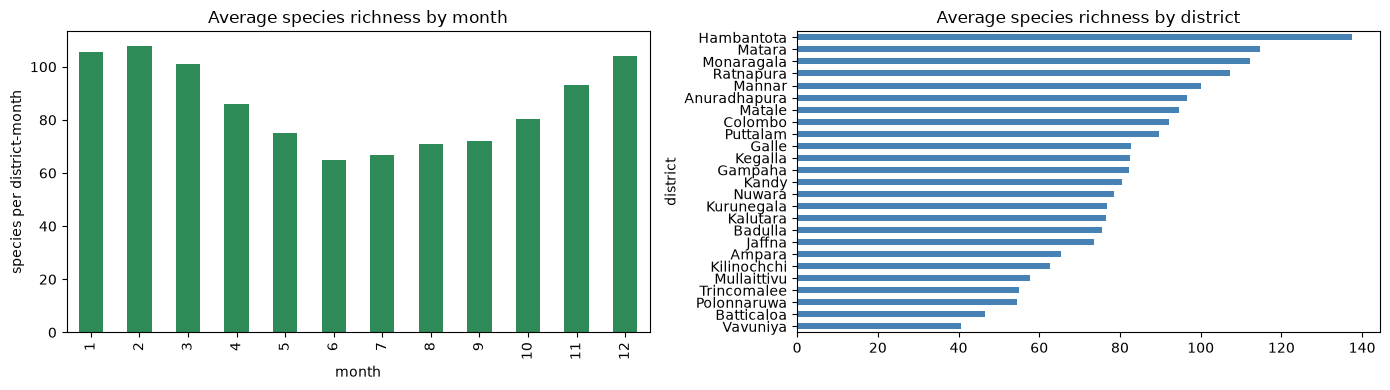

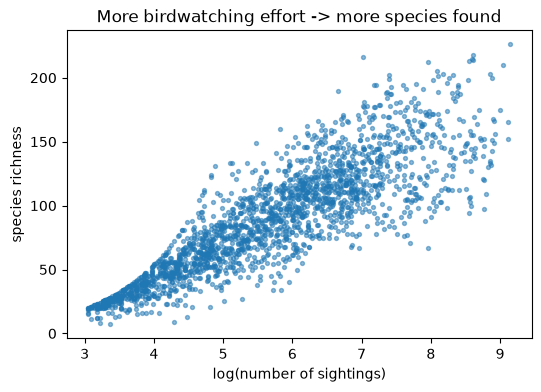

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
agg.groupby("month")["species_richness"].mean().plot(kind="bar", ax=ax[0], color="seagreen")
ax[0].set_title("Average species richness by month")
ax[0].set_ylabel("species per district-month")
(agg.groupby("district")["species_richness"].mean().sort_values()
    .plot(kind="barh", ax=ax[1], color="steelblue"))
ax[1].set_title("Average species richness by district")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(agg["log_records"], agg["species_richness"], s=8, alpha=.5)
plt.xlabel("log(number of sightings)"); plt.ylabel("species richness")
plt.title("More birdwatching effort -> more species found"); plt.show()

## 7. Features, target and train/test split

In [7]:
CAT_FEATURES = ["district"]
NUM_FEATURES = ["year", "month_sin", "month_cos", "migrant_season", "log_records",
                "lat", "lon"] + ENV_COLS
TARGET = "species_richness"

X = agg[CAT_FEATURES + NUM_FEATURES]
y = agg[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("train:", X_train.shape, "test:", X_test.shape)

def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES),
    ])

def ann():
    # Neural network; target is scaled too, which helps the network train
    return TransformedTargetRegressor(
        regressor=MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3,
                               early_stopping=True, max_iter=2000, random_state=SEED),
        transformer=StandardScaler())

train: (1663, 18) test: (416, 18)


## 8. Define the models

In [8]:
base_models = {
    # Baselines
    "Mean baseline":        DummyRegressor(strategy="mean"),
    "Linear Regression":    LinearRegression(),
    "Single Decision Tree": DecisionTreeRegressor(random_state=SEED),
    # Bagging
    "Bagging (Trees)":      BaggingRegressor(DecisionTreeRegressor(), n_estimators=200,
                                             random_state=SEED, n_jobs=-1),
    "Random Forest":        RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                                  random_state=SEED, n_jobs=-1),
    # Boosting
    "AdaBoost":             AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=300,
                                              learning_rate=0.05, random_state=SEED),
    "LightGBM":             LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=15,
                                          min_child_samples=10, subsample=0.8, subsample_freq=1,
                                          colsample_bytree=0.8, random_state=SEED, verbose=-1),
    # Neural network
    "ANN (MLP)":            ann(),
}

# Stacking: RF + LightGBM + ANN, combined by a Ridge regression "meta-model"
base_models["Stacking (RF+LGBM+ANN)"] = StackingRegressor(
    estimators=[("rf", base_models["Random Forest"]),
                ("lgbm", base_models["LightGBM"]),
                ("ann", ann())],
    final_estimator=RidgeCV(), cv=5, n_jobs=-1)

GROUP = {"Mean baseline": "Baseline", "Linear Regression": "Baseline",
         "Single Decision Tree": "Baseline", "Bagging (Trees)": "Bagging",
         "Random Forest": "Bagging", "AdaBoost": "Boosting", "LightGBM": "Boosting",
         "ANN (MLP)": "Neural net", "Stacking (RF+LGBM+ANN)": "Stacking"}

## 9. Train and evaluate every model on the SAME test set

In [9]:
def evaluate(name, y_true, y_pred):
    return {"model": name, "family": GROUP.get(name, "Hybrid"),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

fitted, results, test_preds = {}, [], {}
for name, model in base_models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name], test_preds[name] = pipe, pred
    results.append(evaluate(name, y_test, pred))
    print(f"{name:28s} R2 = {results[-1]['R2']:.3f}")

Mean baseline                R2 = -0.001
Linear Regression            R2 = 0.870
Single Decision Tree         R2 = 0.796
Bagging (Trees)              R2 = 0.889
Random Forest                R2 = 0.887
AdaBoost                     R2 = 0.863
LightGBM                     R2 = 0.916
ANN (MLP)                    R2 = 0.881
Stacking (RF+LGBM+ANN)       R2 = 0.915


## 10. Hybrid models: Random Forest + ANN

In [10]:
# Hybrid A - Residual hybrid: RF learns the main pattern, then an ANN learns what RF got wrong.
# We use out-of-fold RF predictions so the ANN sees honest errors (no leakage).
rf_pipe = fitted["Random Forest"]
oof_rf = cross_val_predict(Pipeline([("prep", make_preprocessor()),
                                     ("model", RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                                                     random_state=SEED, n_jobs=-1))]),
                           X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED))
residuals = y_train - oof_rf
ann_resid = Pipeline([("prep", make_preprocessor()), ("model", ann())]).fit(X_train, residuals)
pred_hybrid_resid = rf_pipe.predict(X_test) + ann_resid.predict(X_test)
results.append(evaluate("Hybrid RF + ANN (residual)", y_test, pred_hybrid_resid))
test_preds["Hybrid RF + ANN (residual)"] = pred_hybrid_resid

# Hybrid B - Weighted blend: average RF and ANN, weight chosen on out-of-fold train predictions
oof_ann = cross_val_predict(Pipeline([("prep", make_preprocessor()), ("model", ann())]),
                            X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED))
weights = np.linspace(0, 1, 21)
best_w = weights[np.argmin([mean_squared_error(y_train, w * oof_rf + (1 - w) * oof_ann) for w in weights])]
pred_blend = best_w * rf_pipe.predict(X_test) + (1 - best_w) * fitted["ANN (MLP)"].predict(X_test)
results.append(evaluate("Hybrid RF + ANN (blend)", y_test, pred_blend))
test_preds["Hybrid RF + ANN (blend)"] = pred_blend
print("Best RF weight in blend:", best_w)

Best RF weight in blend: 0.45


## 11. Compare

                         model      family     MAE    RMSE     R2
0                     LightGBM    Boosting   9.287  12.666  0.916
1       Stacking (RF+LGBM+ANN)    Stacking   9.213  12.733  0.915
2      Hybrid RF + ANN (blend)      Hybrid   9.893  13.796  0.900
3   Hybrid RF + ANN (residual)      Hybrid  10.293  13.895  0.898
4              Bagging (Trees)     Bagging  10.482  14.513  0.889
5                Random Forest     Bagging  10.558  14.672  0.887
6                    ANN (MLP)  Neural net  11.051  15.032  0.881
7            Linear Regression    Baseline  11.782  15.752  0.870
8                     AdaBoost    Boosting  12.047  16.150  0.863
9         Single Decision Tree    Baseline  14.921  19.677  0.796
10               Mean baseline    Baseline  36.439  43.638 -0.001


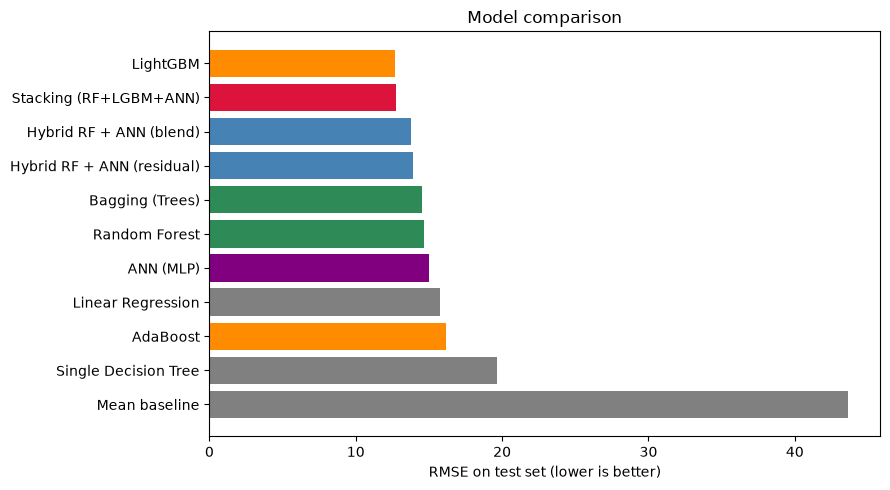

In [11]:
res = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
print(res.round(3))

plt.figure(figsize=(9, 5))
colors = {"Baseline": "grey", "Bagging": "seagreen", "Boosting": "darkorange",
          "Neural net": "purple", "Stacking": "crimson", "Hybrid": "steelblue"}
plt.barh(res["model"], res["RMSE"], color=res["family"].map(colors))
plt.gca().invert_yaxis(); plt.xlabel("RMSE on test set (lower is better)")
plt.title("Model comparison"); plt.tight_layout(); plt.show()

## 12. Predicted vs actual for the best model

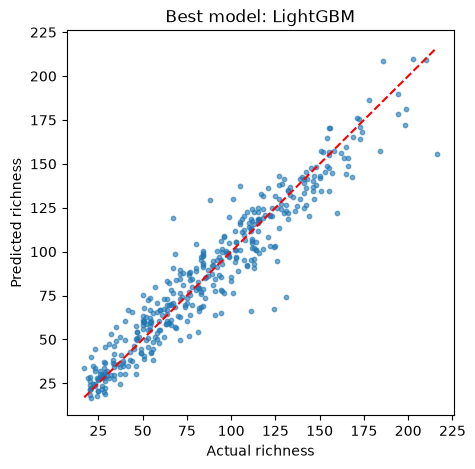

In [12]:
best_name = res.iloc[0]["model"]
plt.figure(figsize=(5, 5))
plt.scatter(y_test, test_preds[best_name], s=10, alpha=.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--"); plt.xlabel("Actual richness"); plt.ylabel("Predicted richness")
plt.title(f"Best model: {best_name}"); plt.show()

## 13. Which features matter? (permutation importance on the test set)

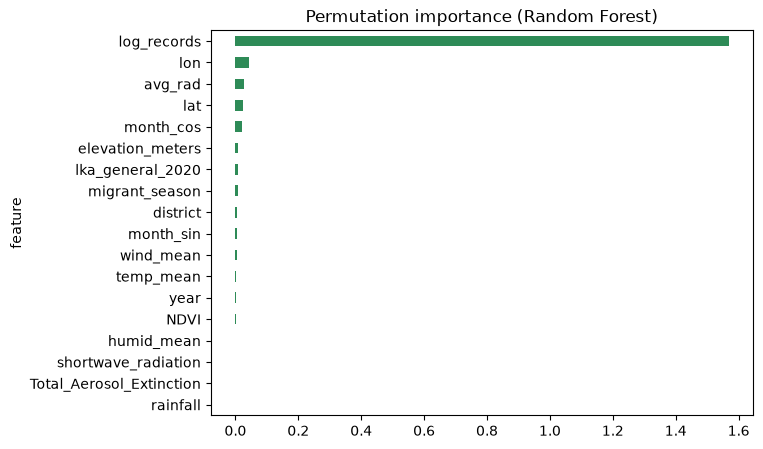

,feature,importance
5,log_records,1.567929
7,lon,0.042983
15,avg_rad,0.026635
6,lat,0.022629
3,month_cos,0.020224
9,elevation_meters,0.009589
16,lka_general_2020,0.006819
4,migrant_season,0.006652
0,district,0.006145
2,month_sin,0.005028


In [13]:
imp = permutation_importance(fitted["Random Forest"], X_test, y_test, n_repeats=10,
                             random_state=SEED, n_jobs=-1)
imp_df = (pd.DataFrame({"feature": X_test.columns, "importance": imp.importances_mean})
            .sort_values("importance", ascending=False))
imp_df.plot(kind="barh", x="feature", y="importance", figsize=(7, 5), legend=False, color="seagreen")
plt.gca().invert_yaxis(); plt.title("Permutation importance (Random Forest)"); plt.show()
imp_df

## 14. Save everything the dashboard needs

In [14]:
joblib.dump({"Random Forest": fitted["Random Forest"],
             "LightGBM": fitted["LightGBM"],
             "ANN (MLP)": fitted["ANN (MLP)"],
             "Stacking (RF+LGBM+ANN)": fitted["Stacking (RF+LGBM+ANN)"],
             "ANN residual": ann_resid,
             "blend_weight": float(best_w)}, "artifacts/models.joblib", compress=3)
res.to_csv("artifacts/results.csv", index=False)
imp_df.to_csv("artifacts/feature_importance.csv", index=False)
agg.to_csv("artifacts/district_month.csv", index=False)
df.sample(min(20000, len(df)), random_state=SEED)[["decimalLatitude", "decimalLongitude", "district"]] \
  .rename(columns={"decimalLatitude": "lat", "decimalLongitude": "lon"}) \
  .to_csv("artifacts/map_sample.csv", index=False)
json.dump({"cat": CAT_FEATURES, "num": NUM_FEATURES, "env": ENV_COLS},
          open("artifacts/features.json", "w"))
print("Saved to artifacts/")

Saved to artifacts/


## 15. Interpretation

The 1.55 million sightings became **2,079 district-month rows** (1,663 train / 416 test). Every model was scored on the same 416 test rows.

- **Bagging vs single tree:** The single decision tree had an RMSE of **19.68** (R² 0.796), while Random Forest had **14.67** (R² 0.887). One deep tree memorises noise in the training data (high variance). Bagging trains many trees on bootstrap samples and averages them, which cancels out much of that variance.
- **Random Forest vs plain bagging:** Random Forest (RMSE **14.67**) was very slightly worse than plain bagging (**14.51**). Random feature selection is meant to make the trees less similar, but one feature (`log_records`) dominates this problem. Hiding it from some splits weakens individual trees more than the extra diversity helps.
- **Boosting vs bagging:** LightGBM was the best model overall, with an RMSE of **12.67**, MAE **9.29** and R² **0.916**. Boosting fits each new tree to the remaining error, so it captured finer non-linear patterns (e.g. effort × season × location) that averaging independent trees missed. AdaBoost was much weaker (RMSE **16.15**, below even linear regression): with shallow trees and a small learning rate it reduced bias less effectively than gradient boosting.
- **ANN alone:** The ANN scored an RMSE of **15.03** and R² of **0.881**, behind the tree ensembles. Neural networks usually need more data than tree models, and with only about 2,000 tabular rows the tree ensembles were stronger.
- **Stacking:** Stacking (RF + LightGBM + ANN → Ridge) had an RMSE of **12.73**, essentially tied with LightGBM (**12.67**), and it actually had the **lowest MAE (9.21 vs 9.29)**. RF and LightGBM are both tree models, so their errors overlap. The meta-model therefore mostly trusted LightGBM, and the ANN added only a small correction.
- **Hybrid RF + ANN:** Both hybrids **improved on Random Forest**. The residual hybrid cut RMSE from **14.67 to 13.89**, so the ANN learned part of what the RF got wrong. Trees predict in flat steps, and the ANN smooths those step-shaped errors. The weighted blend did even better (RMSE **13.80**, R² 0.900), with an RF weight of **0.45**. That means the out-of-fold data favoured a near-equal mix, slightly leaning to the ANN: the two model types make different kinds of mistakes, so averaging them cancels some of each. Neither hybrid beat LightGBM.
- **Linear regression is a strong baseline (R² 0.870):** Most of the variation in richness is explained by survey effort (`log_records`), which has a near-linear relationship with richness. The ensembles win by modelling the remaining non-linear part, which is why the gap between linear regression and LightGBM is about 3 species of RMSE.
- **Feature importance (permutation importance, Random Forest):** `log_records` was by far the most important feature (**1.57**, against **0.04** for the next one). More birdwatching finds more species, so effort must be modelled. After that come **longitude (0.043)**, **night-time lights `avg_rad` (0.027)**, **latitude (0.023)** and **season (`month_cos` 0.020, `migrant_season` 0.007)**. Location separates the dry-zone/coastal districts from the wet-zone and hill-country districts. Night-time lights act as a proxy for urbanisation. Season reflects winter migrants arriving from about September to April. Elevation (0.010) reflects hill-country habitat with more endemics. NDVI, rainfall and aerosol had almost no importance once location and season were known, probably because district-month averages of these values mostly repeat what location and month already say. *(Importance was computed on Random Forest; LightGBM, the best model, may rank features slightly differently.)*
- **Limitation:** Citizen-science data has sampling bias. Popular birding spots (e.g. Sinharaja, Yala) are over-recorded, so measured richness partly reflects where and how much birders go, not only true diversity. The random split also lets the same district appear in both train and test, so performance on a completely unseen district or future year would likely be lower.